# Tract Statistics

Alex Broughton

## Introduction

Weak-lensing maps are sensitive to both the source sample and the local image quality.
This notebook builds a tract-level summary of those ingredients for the full DP2
footprint.

Object table: each tract is stored as one Butler object dataset (tract is the only
required dimension). Columns are subset with parameters={"columns": ...}, following the
DP2 catalog tutorials
([104.4 Catalog queries with the Butler](https://dp2.lsst.io/tutorials/notebook/104/notebook-104-4.html),
[201.01 Object table](https://dp2.lsst.io/tutorials/notebook/201/notebook-201-01.html)).
The selection function is copied from dp2_shearmap.ipynb.

Survey property maps: PSF size, PSF $e_1$/$e_2$, and the PSF-flux 5σ magnitude limit
are HealSparse products, one map per band for the whole survey
([survey property maps](https://dp2.lsst.io/products/maps/sp_maps.html),
[301.1 DP2 overview](https://dp2.lsst.io/tutorials/notebook/301/notebook-301-1.html),
and _tutorials/survey-property-maps.ipynb in this repo).
Maps are loaded once, degraded on read, and sampled at the positions of the selected
galaxies, so the per-tract mean and median describe the source sample rather than empty
sky.

The PSF size map stores a Gaussian $\sigma$ in pixels. Following the DP2 overview
tutorial, FWHM in arcseconds is $\sigma \times 0.2''/\mathrm{pix} \times 2\sqrt{2\ln 2}$.


## 1.0 Setup

### 1.1 Imports and configuration

Everything tunable lives in CONFIG. Selection thresholds match dp2_shearmap.ipynb.
Set MAX_TRACTS to a small integer for a dry run; set RESUME to skip tracts already
written to the output table.


In [1]:
import gc
from pathlib import Path

import numpy as np
import matplotlib.pyplot as plt
import astropy.units as u
from astropy.coordinates import SkyCoord
from astropy.table import Table
from tqdm.auto import tqdm

from lsst.daf.butler import Butler

%matplotlib inline

# ApJ-style matplotlib defaults: Times-like serif + STIX mathtext.
from matplotlib import rcParams

APJ_RCPARAMS = {
    "font.family": "serif",
    "font.serif": ["Times New Roman", "Times", "DejaVu Serif"],
    "font.size": 11,
    "axes.labelsize": 12,
    "axes.titlesize": 12,
    "xtick.labelsize": 10,
    "ytick.labelsize": 10,
    "legend.fontsize": 10,
    "axes.linewidth": 0.8,
    "axes.unicode_minus": False,
    "axes.formatter.use_mathtext": True,
    "mathtext.fontset": "stix",
    "mathtext.rm": "serif",
    "mathtext.it": "serif:italic",
    "mathtext.bf": "serif:bold",
    "text.usetex": False,
    "xtick.direction": "in",
    "ytick.direction": "in",
    "xtick.top": True,
    "ytick.right": True,
    "xtick.minor.visible": True,
    "ytick.minor.visible": True,
    "xtick.major.size": 5.0,
    "ytick.major.size": 5.0,
    "xtick.minor.size": 2.5,
    "ytick.minor.size": 2.5,
    "xtick.major.width": 0.8,
    "ytick.major.width": 0.8,
    "xtick.minor.width": 0.6,
    "ytick.minor.width": 0.6,
    "lines.linewidth": 1.0,
    "lines.markersize": 4.0,
    "errorbar.capsize": 2.0,
    "legend.frameon": False,
    "legend.handlelength": 1.4,
    "figure.dpi": 120,
    "figure.facecolor": "white",
    "axes.facecolor": "white",
    "savefig.dpi": 300,
    "savefig.bbox": "tight",
    "savefig.pad_inches": 0.05,
    "savefig.facecolor": "white",
    "pdf.fonttype": 42,
    "ps.fonttype": 42,
    "image.cmap": "turbo",
}
rcParams.update(APJ_RCPARAMS)

# Repo layout: _data/ holds external inputs, output/ holds generated tables/catalogs, plots/ holds figures.
ROOT = Path.cwd().resolve().parent if Path.cwd().name == "notebooks" else Path.cwd().resolve()
DATA_DIR = ROOT / "_data"
OUTPUT_DIR = ROOT / "output"
PLOTS_DIR = ROOT / "plots"
for _d in (OUTPUT_DIR, PLOTS_DIR):
    _d.mkdir(parents=True, exist_ok=True)
print("repo root:", ROOT)


repo root: /home/a/abrought/dp2/v2/dp2-clusters-shear-mapping


In [2]:
CONFIG = {
    # --- Butler ----------------------------------------------------------
    "REPO": "/sdf/data/rubin/repo/dp2_prep",
    "COLLECTION": "LSSTCam/runs/DRP/DP2/v30_0_0/DM-53881/stage3",
    "SKYMAP": "lsst_cells_v2",
    "INSTRUMENT": "LSSTCam",
    "OBJECT_DATASET": "object",
    "BAND": "i",
    # --- Source selection, copied from dp2_shearmap.ipynb -----------------
    "SNR_MIN": 5.0,
    "RESO_FACTOR_MIN": 0.125,
    "COLOR_ABS_MAX": 5.0,
    "EXTENDEDNESS_MIN": 0.2,
    "E_SQ_MAX": 4.0,
    "T_MAX_ARCSEC2": None,
    "PIX_SCALE_ARCSEC": 0.2,
    "RED_SEQ_SLOPE": 2.276,
    "RED_SEQ_INTERCEPT": -0.20,
    # --- Survey property maps --------------------------------------------
    # Native maps are nside_sparse = 32768; degrade on read (DP2 tutorial 301.1).
    "DEGRADE_NSIDE": 1024,
    "PSF_SIZE_MAP": "deepCoadd_psf_size_consolidated_map_weighted_mean",
    "PSF_E1_MAP": "deepCoadd_psf_e1_consolidated_map_weighted_mean",
    "PSF_E2_MAP": "deepCoadd_psf_e2_consolidated_map_weighted_mean",
    "PSF_MAGLIM_MAP": "deepCoadd_psf_maglim_consolidated_map_weighted_mean",
    # --- Run control -----------------------------------------------------
    "MAX_TRACTS": None,  # int for a partial run; None = every object-table tract
    "RESUME": True,  # skip tracts already in the output table
    "OUTPUT_TABLE": "dp2_shapehsm_tract_stats.ecsv",
}

# FWHM / sigma for a Gaussian; the DP2 overview quotes 2.35.
CONFIG["SIGMA_TO_FWHM"] = float(2.0 * np.sqrt(2.0 * np.log(2.0)))

print("output dir:", OUTPUT_DIR)
print(
    "selection: SNR_MIN =",
    CONFIG["SNR_MIN"],
    "| RESO_FACTOR_MIN =",
    CONFIG["RESO_FACTOR_MIN"],
    "| RED_SEQ_INTERCEPT =",
    CONFIG["RED_SEQ_INTERCEPT"],
)
print(
    "PSF FWHM (arcsec) = sigma_pix x",
    CONFIG["PIX_SCALE_ARCSEC"],
    "x",
    f"{CONFIG['SIGMA_TO_FWHM']:.4f}",
)


output dir: /home/a/abrought/dp2/v2/dp2-clusters-shear-mapping/_data
selection: SNR_MIN = 5.0 | RESO_FACTOR_MIN = 0.125 | RED_SEQ_INTERCEPT = -0.2
PSF FWHM (arcsec) = sigma_pix x 0.2 x 2.3548


### 1.2 Butler and skymap

One client, pointed at the DP2 stage-3 collection that holds both the object tables
and the consolidated survey property maps. The skymap gives each tract's area.


In [3]:
butler = Butler(
    CONFIG["REPO"],
    collections=[CONFIG["COLLECTION"]],
    skymap=CONFIG["SKYMAP"],
    instrument=CONFIG["INSTRUMENT"],
)
skymap = butler.get("skyMap", dataId={"skymap": CONFIG["SKYMAP"]})


def tract_area_deg2(skymap, tract):
    """Area of a tract's unique (inner) region in deg^2."""
    region = skymap[tract].inner_sky_region
    if hasattr(region, "getArea"):  # sphgeom.Box, as in rings skymaps
        sr = region.getArea()
    else:  # convex polygon: sum the solid angles of a triangle fan
        v = np.array([[p.x(), p.y(), p.z()] for p in region.getVertices()])
        a = v[0]
        sr = sum(
            2 * np.arctan2(abs(a @ np.cross(b, c)), 1 + a @ b + b @ c + c @ a)
            for b, c in zip(v[1:-1], v[2:])
        )
    return float(sr * (180.0 / np.pi) ** 2)


### 1.3 Tracts

The object table is stored by tract
([104.4](https://dp2.lsst.io/tutorials/notebook/104/notebook-104-4.html)).
Enumerate every tract that has one in this collection.


In [4]:
def available_tracts(dataset_type, **data_id):
    """Sorted tract ids holding at least one dataset of this type."""
    data_ids = butler.registry.queryDataIds(
        ["tract"],
        datasets=dataset_type,
        collections=CONFIG["COLLECTION"],
        skymap=CONFIG["SKYMAP"],
        **data_id,
    )
    return sorted({int(d["tract"]) for d in data_ids})


tracts = available_tracts(CONFIG["OBJECT_DATASET"])
if CONFIG["MAX_TRACTS"] is not None:
    tracts = tracts[: int(CONFIG["MAX_TRACTS"])]

print(f"object tracts in {CONFIG['COLLECTION']}: {len(tracts)}")
print("first / last:", tracts[0], "/", tracts[-1])


object tracts in LSSTCam/runs/DRP/DP2/v30_0_0/DM-53881/stage3: 2177
first / last: 2054 / 13041


## 2.0 Source selection

The cuts are those of dp2_shearmap.ipynb: clean measurement and pixel flags, deblended
model source, $|e| \le 2$, resolution factor, extendedness and griz Sersic S/N,
adjacent-band colors, and the red-sequence veto. Only the columns those cuts need are
read.


In [5]:
FLAG_COLUMNS = [
    "i_i_flag",
    "i_iPSF_flag",
    "i_hsmShapeRegauss_flag",
    "i_gaapFlux_flag",
    "sersic_no_data_flag",
    "sersic_unknown_flag",
    "shape_flag",
    "i_pixelFlags_bad",
    "i_pixelFlags_nodata",
    "i_pixelFlags_edge",
    "i_pixelFlags_saturatedCenter",
    "i_pixelFlags_crCenter",
    "i_pixelFlags_interpolatedCenter",
    "i_pixelFlags_suspectCenter",
]

WANTED_COLUMNS = [
    "objectId",
    "coord_ra",
    "coord_dec",
    "detect_isDeblendedModelSource",
    "griz_model_extendedness",
    "i_hsmShapeRegauss_e1",
    "i_hsmShapeRegauss_e2",
    "i_ixx",
    "i_iyy",
    "i_ixxPSF",
    "i_iyyPSF",
    "i_inputCount",
    "g_sersicFlux",
    "g_sersicFluxErr",
    "r_sersicFlux",
    "r_sersicFluxErr",
    "i_sersicFlux",
    "i_sersicFluxErr",
    "z_sersicFlux",
    "z_sersicFluxErr",
] + FLAG_COLUMNS


def object_data_id(tract):
    return {"tract": int(tract), "skymap": CONFIG["SKYMAP"]}


# Intersect with the schema of one tract so a missing column cannot break the loop.
try:
    _names = set(
        butler.get(
            CONFIG["OBJECT_DATASET"],
            dataId=object_data_id(tracts[0]),
            storageClass="ArrowSchema",
        ).names
    )
except Exception as exc:
    print("ArrowSchema unavailable, reading one full table instead:", exc)
    _names = set(
        butler.get(CONFIG["OBJECT_DATASET"], dataId=object_data_id(tracts[0])).colnames
    )

OBJECT_COLUMNS = [c for c in WANTED_COLUMNS if c in _names]
FLAG_COLUMNS = [c for c in FLAG_COLUMNS if c in _names]
print("missing columns:", [c for c in WANTED_COLUMNS if c not in _names] or "none")
print(f"reading {len(OBJECT_COLUMNS)} of {len(_names)} columns per tract")


def load_object_table(tract):
    """Object table for one tract, restricted to the selection columns."""
    return butler.get(
        CONFIG["OBJECT_DATASET"],
        dataId=object_data_id(tract),
        parameters={"columns": OBJECT_COLUMNS},
    )


ArrowSchema unavailable, reading one full table instead: The new storage class (ArrowSchema) is not compatible with the existing storage class (ArrowAstropy).
missing columns: none
reading 34 of 1224 columns per tract


In [6]:
def _col(tbl, name):
    """Column as a float64 numpy array."""
    return np.asarray(tbl[name], dtype=np.float64)


def flux_to_abmag(flux_njy):
    """Convert nJy fluxes to AB magnitudes; non-positive or non-finite fluxes become NaN."""
    flux = np.asarray(flux_njy, dtype=np.float64)
    mag = np.full(flux.shape, np.nan, dtype=np.float64)
    good = np.isfinite(flux) & (flux > 0.0)
    mag[good] = (flux[good] * u.nJy).to(u.ABmag).value
    return mag


def selection_mask(data):
    """Combined selection mask and the per-group masks that build it.

    Identical to dp2_shearmap.ipynb.
    """
    n = len(data)
    flag_columns = [c for c in FLAG_COLUMNS if c in data.colnames]

    flags_ok = np.ones(n, dtype=bool)
    for name in flag_columns:
        flags_ok &= ~np.asarray(data[name], dtype=bool)
    if "i_inputCount" in data.colnames:
        flags_ok &= np.asarray(data["i_inputCount"]) > 0

    primary_ok = np.asarray(data["detect_isDeblendedModelSource"], dtype=bool)

    e_sq = _col(data, "i_hsmShapeRegauss_e1") ** 2 + _col(data, "i_hsmShapeRegauss_e2") ** 2
    shape_ok = e_sq <= CONFIG["E_SQ_MAX"]

    t_obj = _col(data, "i_ixx") + _col(data, "i_iyy")
    with np.errstate(divide="ignore", invalid="ignore"):
        reso = 1.0 - (_col(data, "i_ixxPSF") + _col(data, "i_iyyPSF")) / t_obj
    reso_ok = reso > CONFIG["RESO_FACTOR_MIN"]

    mag = {b: flux_to_abmag(_col(data, f"{b}_sersicFlux")) for b in "griz"}
    with np.errstate(divide="ignore", invalid="ignore"):
        snr = {b: _col(data, f"{b}_sersicFlux") / _col(data, f"{b}_sersicFluxErr") for b in "griz"}

    snr_min = CONFIG["SNR_MIN"]
    detect_ok = _col(data, "griz_model_extendedness") > CONFIG["EXTENDEDNESS_MIN"]
    for b in "griz":
        detect_ok &= snr[b] > snr_min

    color_max = CONFIG["COLOR_ABS_MAX"]
    gi = mag["g"] - mag["i"]
    rz = mag["r"] - mag["z"]
    color_ok = np.abs(mag["g"] - mag["r"]) < color_max
    color_ok &= np.abs(mag["r"] - mag["i"]) < color_max
    color_ok &= np.abs(mag["i"] - mag["z"]) < color_max
    color_ok &= np.isfinite(gi) & np.isfinite(rz)
    # Red-sequence veto: drop objects above the line in (r-z, g-i).
    color_ok &= ~(gi > CONFIG["RED_SEQ_SLOPE"] * rz + CONFIG["RED_SEQ_INTERCEPT"])

    size_ok = np.ones(n, dtype=bool)
    if CONFIG["T_MAX_ARCSEC2"] is not None:
        size_ok = t_obj < CONFIG["T_MAX_ARCSEC2"] / CONFIG["PIX_SCALE_ARCSEC"] ** 2

    groups = {
        "measurement + pixel flags": flags_ok,
        "deblended model source": primary_ok,
        "|e| <= 2": shape_ok,
        f"reso_factor > {CONFIG['RESO_FACTOR_MIN']}": reso_ok,
        f"extendedness + S/N > {snr_min:g}": detect_ok,
        "colors + red sequence": color_ok,
        "size": size_ok,
    }
    mask = np.ones(n, dtype=bool)
    for cut in groups.values():
        mask &= cut
    return mask, groups


## 3.0 Survey property maps

Load the four i-band HealSparse maps used for the per-tract image-quality statistics.
parameters={"degrade_nside": ...} downsamples on read so the full-sky maps fit in
interactive memory
([301.1](https://dp2.lsst.io/tutorials/notebook/301/notebook-301-1.html),
[survey property maps tutorial](https://dp2.lsst.io/tutorials/index.html)).

| Dataset | Quantity | Native units |
| --- | --- | --- |
| deepCoadd_psf_size_consolidated_map_weighted_mean | PSF $\sigma$ (determinant radius) | pixel |
| deepCoadd_psf_e1_consolidated_map_weighted_mean | PSF ellipticity $e_1$ | — |
| deepCoadd_psf_e2_consolidated_map_weighted_mean | PSF ellipticity $e_2$ | — |
| deepCoadd_psf_maglim_consolidated_map_weighted_mean | PSF-flux 5σ limit | mag AB |


In [7]:
def load_property_map(dataset_type):
    """Degraded HealSparse map for CONFIG['BAND']."""
    hsp = butler.get(
        dataset_type,
        dataId={"band": CONFIG["BAND"], "skymap": CONFIG["SKYMAP"]},
        parameters={"degrade_nside": int(CONFIG["DEGRADE_NSIDE"])},
    )
    print(
        f"{dataset_type}: nside_sparse={hsp.nside_sparse}, "
        f"nside_coverage={hsp.nside_coverage}"
    )
    return hsp


hsp_psf_size = load_property_map(CONFIG["PSF_SIZE_MAP"])
hsp_psf_e1 = load_property_map(CONFIG["PSF_E1_MAP"])
hsp_psf_e2 = load_property_map(CONFIG["PSF_E2_MAP"])
hsp_maglim = load_property_map(CONFIG["PSF_MAGLIM_MAP"])


deepCoadd_psf_size_consolidated_map_weighted_mean: nside_sparse=1024, nside_coverage=32
deepCoadd_psf_e1_consolidated_map_weighted_mean: nside_sparse=1024, nside_coverage=32
deepCoadd_psf_e2_consolidated_map_weighted_mean: nside_sparse=1024, nside_coverage=32
deepCoadd_psf_maglim_consolidated_map_weighted_mean: nside_sparse=1024, nside_coverage=32


In [8]:
def map_values_at(hspmap, ra_deg, dec_deg):
    """HealSparse values at RA/Dec (degrees), with sentinel / non-finite entries as NaN."""
    ra = np.asarray(ra_deg, dtype=np.float64)
    dec = np.asarray(dec_deg, dtype=np.float64)
    vals = np.asarray(hspmap.get_values_pos(ra, dec), dtype=np.float64)
    bad = ~np.isfinite(vals)
    sentinel = getattr(hspmap, "sentinel", None)
    if sentinel is not None and np.isfinite(sentinel):
        bad |= vals == sentinel
    vals[bad] = np.nan
    return vals


def nan_mean_median(x):
    """Mean and median of finite values; NaN if none."""
    x = np.asarray(x, dtype=np.float64)
    x = x[np.isfinite(x)]
    if x.size == 0:
        return np.nan, np.nan
    return float(np.mean(x)), float(np.median(x))


def circular_mean_ra(ra_deg):
    """Circular mean RA in [0, 360), so a tract on RA = 0 is not averaged across the seam."""
    ra_rad = np.deg2rad(np.asarray(ra_deg, dtype=np.float64))
    return float(np.rad2deg(np.arctan2(np.mean(np.sin(ra_rad)), np.mean(np.cos(ra_rad)))) % 360.0)


## 4.0 Per-tract measurement

For each tract: load the object table, apply the selection, sample the four maps at the
selected galaxies, and reduce to mean / median. The source count is the number of rows
that pass the cuts.


In [9]:
def process_tract(tract):
    """Return a dict of per-tract statistics, or a dict with an 'error' key."""
    tract = int(tract)
    try:
        data = load_object_table(tract)
        n_before = int(len(data))
        if n_before == 0:
            return {"tract": tract, "error": "empty object table"}

        mask, _ = selection_mask(data)
        n_gal = int(mask.sum())
        ra = _col(data, "coord_ra")
        dec = _col(data, "coord_dec")
        ra_sel = ra[mask]
        dec_sel = dec[mask]

        # Tract location from all objects (stable even if the selection is empty).
        ra_center = circular_mean_ra(ra)
        dec_center = float(np.mean(dec))

        if n_gal > 0:
            psf_sigma = map_values_at(hsp_psf_size, ra_sel, dec_sel)
            psf_fwhm = psf_sigma * CONFIG["PIX_SCALE_ARCSEC"] * CONFIG["SIGMA_TO_FWHM"]
            psf_e1 = map_values_at(hsp_psf_e1, ra_sel, dec_sel)
            psf_e2 = map_values_at(hsp_psf_e2, ra_sel, dec_sel)
            maglim = map_values_at(hsp_maglim, ra_sel, dec_sel)
            # Depth maps can return a non-positive sentinel on uncovered pixels.
            maglim = np.where(np.isfinite(maglim) & (maglim > 0.0), maglim, np.nan)
        else:
            psf_fwhm = psf_e1 = psf_e2 = maglim = np.array([], dtype=np.float64)

        fwhm_mean, fwhm_median = nan_mean_median(psf_fwhm)
        e1_mean, e1_median = nan_mean_median(psf_e1)
        e2_mean, e2_median = nan_mean_median(psf_e2)
        maglim_mean, maglim_median = nan_mean_median(maglim)

        return {
            "tract": tract,
            "ra_center": ra_center,
            "dec_center": dec_center,
            "n_before": n_before,
            "n_gal": n_gal,
            "psf_fwhm_mean": fwhm_mean,
            "psf_fwhm_median": fwhm_median,
            "psf_e1_mean": e1_mean,
            "psf_e1_median": e1_median,
            "psf_e2_mean": e2_mean,
            "psf_e2_median": e2_median,
            "maglim_mean": maglim_mean,
            "maglim_median": maglim_median,
        }
    except Exception as exc:
        return {"tract": tract, "error": repr(exc)}


### 4.1 One-tract check

Run the first tract in the list (COSMOS is 9813 when it is present) and print the
per-cut losses plus the image-quality numbers. This is the place to catch a column or
map-name problem before the full loop.


In [10]:
check_tract = 9813 if 9813 in tracts else tracts[0]
check_data = load_object_table(check_tract)
check_mask, check_groups = selection_mask(check_data)
print(f"tract {check_tract}: {len(check_data):,} objects")
print(f"{'cut':<32} {'n pass':>12}")
print("-" * 46)
print(f"{'all objects':<32} {len(check_data):>12,}")
running = np.ones(len(check_data), dtype=bool)
for name, cut in check_groups.items():
    running &= cut
    print(f"{name:<32} {int(running.sum()):>12,}")

check_row = process_tract(check_tract)
for key, val in check_row.items():
    print(f"{key}: {val}")
del check_data, check_mask, check_groups
gc.collect()


tract 9813: 865,287 objects
cut                                    n pass
----------------------------------------------
all objects                           865,287
measurement + pixel flags             541,165
deblended model source                485,061
|e| <= 2                              429,553
reso_factor > 0.125                   399,845
extendedness + S/N > 5                284,831
colors + red sequence                 184,656
size                                  184,656
tract: 9813
ra_center: 150.2482292616206
dec_center: 2.2316217882281015
n_before: 865287
n_gal: 184656
psf_fwhm_mean: 1.0334677035928705
psf_fwhm_median: 1.033183693863163
psf_e1_mean: -0.005388490302892568
psf_e1_median: -0.005312759726328041
psf_e2_mean: -0.017224027820370757
psf_e2_median: -0.017224269291560807
maglim_mean: 25.95355498023212
maglim_median: 25.95341674962694


2530

## 5.0 Loop over all tracts

Failures are recorded and skipped so one bad tract cannot stop the run. With
RESUME = True, tracts already in the output ECSV are left alone. The table is
rewritten after every tract so a killed job still leaves a usable file. The table
and any failures list are written to output/.


In [11]:
output_path = OUTPUT_DIR / CONFIG["OUTPUT_TABLE"]
rows = []
done = set()

if CONFIG["RESUME"] and output_path.is_file():
    existing = Table.read(output_path)
    rows = [dict(zip(existing.colnames, row)) for row in existing]
    done = {int(r["tract"]) for r in rows}
    print(f"resume: {len(done)} tracts already in {output_path}")

failures = {}
todo = [t for t in tracts if t not in done]
print(f"processing {len(todo)} of {len(tracts)} tracts")


def write_rows(path, row_dicts):
    if not row_dicts:
        return
    tbl = Table(rows=row_dicts)
    tbl.sort("tract")
    tbl.write(path, overwrite=True)


for tract in tqdm(todo, desc="tracts"):
    res = process_tract(tract)
    if "error" in res:
        failures[res["tract"]] = res["error"]
        tqdm.write(f"tract {res['tract']}: FAILED {res['error']}")
    else:
        rows.append(res)
        write_rows(output_path, rows)
    gc.collect()

summary = Table(rows=rows) if rows else Table()
if len(summary):
    summary.sort("tract")
    summary.write(output_path, overwrite=True)

print(f"wrote {len(summary)} tracts to {output_path}")
if failures:
    fail_path = OUTPUT_DIR / "dp2_shapehsm_tract_stats_failures.txt"
    with open(fail_path, "w") as fh:
        for tid, msg in sorted(failures.items()):
            fh.write(f"{tid}\t{msg}\n")
    print(f"{len(failures)} failures written to {fail_path}")
else:
    print("no failures")

summary


resume: 2164 tracts already in /home/a/abrought/dp2/v2/dp2-clusters-shear-mapping/_data/dp2_shapehsm_tract_stats.ecsv
processing 13 of 2177 tracts


tracts:   0%|          | 0/13 [00:00<?, ?it/s]

tract 4135: FAILED empty object table
tract 5611: FAILED empty object table
tract 5673: FAILED empty object table
tract 7210: FAILED empty object table
tract 7949: FAILED empty object table
tract 7963: FAILED empty object table
tract 8156: FAILED empty object table
tract 8212: FAILED empty object table
tract 8421: FAILED empty object table
tract 11283: FAILED empty object table
tract 11635: FAILED empty object table
tract 11870: FAILED empty object table
tract 13039: FAILED empty object table
wrote 2164 tracts to /home/a/abrought/dp2/v2/dp2-clusters-shear-mapping/_data/dp2_shapehsm_tract_stats.ecsv
13 failures written to /home/a/abrought/dp2/v2/dp2-clusters-shear-mapping/_data/dp2_shapehsm_tract_stats_failures.txt


tract,ra_center,dec_center,n_before,n_gal,psf_fwhm_mean,psf_fwhm_median,psf_e1_mean,psf_e1_median,psf_e2_mean,psf_e2_median,maglim_mean,maglim_median
int64,float64,float64,int64,int64,float64,float64,float64,float64,float64,float64,float64,float64
2054,359.9984979417929,-51.31030099292582,118836,0,nan,nan,nan,nan,nan,nan,nan,nan
2055,2.4220023004696087,-51.1997313585473,167935,0,nan,nan,nan,nan,nan,nan,nan,nan
2056,4.714257370707681,-51.08424741162762,181402,0,nan,nan,nan,nan,nan,nan,nan,nan
2057,6.854742401965945,-51.03688349093169,156857,0,nan,nan,nan,nan,nan,nan,nan,nan
2058,9.01433246274937,-50.90489868133371,32718,0,nan,nan,nan,nan,nan,nan,nan,nan
2078,56.07921666199075,-51.27675296670552,311226,649,1.0395606017881915,1.04471991808753,0.010082107070452737,0.011405519172493724,0.03443070249469471,0.03590915465887814,25.040826554895286,25.05812887024858
2079,58.470419058547606,-51.19407391802168,371100,19744,1.039031083079766,1.0374614265768451,0.0079223279225871,0.006185267508613802,0.024621532539805636,0.02366388837346014,25.313246009948482,25.34775311399739
2080,60.69318412004939,-51.245410351450396,357542,10356,1.011549663603854,1.010175321507797,0.008240217419234443,0.009745313033123365,0.02017983551049833,0.02172847840013796,25.44325471426122,25.478914160720926
2081,63.12960188220475,-51.33512660902535,297158,0,nan,nan,nan,nan,nan,nan,nan,nan


### 5.1 Source density

Galaxies per arcmin$^2$, using the area of each tract's unique (inner) region from the skymap.


In [12]:
summary["area_deg2"] = [tract_area_deg2(skymap, int(t)) for t in summary["tract"]]
summary["gal_density"] = summary["n_gal"] / (summary["area_deg2"] * 3600.0)  # arcmin^-2

## 6.0 Sky plots

Each point is a tract center, colored by the quantity in the table; the colorbar label
names the quantity. Sequential maps use turbo, diverging ellipticity maps use bwr
centered on zero. The Mollweide projection has RA increasing to the left, with galactic
$b = 0, \pm 10^{\circ}$ overplotted.


In [13]:
RA_CENTER_DEG = 0.0

_NICE_FRACS = (1.0, 1.5, 2.0, 2.5, 3.0, 4.0, 5.0, 6.0, 8.0, 10.0)


def ra_dec_to_mollweide(ra_deg, dec_deg):
    """Mollweide lon/lat in radians, RA_CENTER_DEG at x = 0.

    Longitude is negated so RA increases to the left, matching hp.mollview.
    """
    lon_deg = -((np.asarray(ra_deg, dtype=float) - RA_CENTER_DEG + 180.0) % 360.0 - 180.0)
    return np.radians(lon_deg), np.radians(np.asarray(dec_deg, dtype=float))


def galactic_b_curve(b_deg, n=2000):
    """Mollweide coordinates of a curve of constant galactic latitude."""
    l_deg = np.linspace(0.0, 360.0, n, endpoint=False)
    gal = SkyCoord(l=l_deg * u.deg, b=np.full(n, float(b_deg)) * u.deg, frame="galactic")
    icrs = gal.transform_to("icrs")
    return ra_dec_to_mollweide(icrs.ra.deg, icrs.dec.deg)


def split_at_seam(lon, lat, max_jump=np.deg2rad(95)):
    """Break a sky curve into segments where it wraps across the +/-pi longitude seam."""
    jumps = np.where(np.abs(np.diff(lon)) > max_jump)[0] + 1
    return list(zip(np.split(lon, jumps), np.split(lat, jumps)))


def _nice_step(span, n_intervals=4):
    """Smallest 1-2-5-style step that covers `span` in `n_intervals` pieces."""
    if not np.isfinite(span) or span <= 0:
        return 1.0
    raw = span / float(n_intervals)
    exp = np.floor(np.log10(raw))
    frac = raw / (10.0 ** exp)
    for nice in _NICE_FRACS:
        if frac <= nice + 1e-12:
            return float(nice * 10.0 ** exp)
    return float(10.0 ** (exp + 1.0))


def sequential_limits(values):
    """Rounded vmin, vmax, and five ticks (min, two interior, midpoint, max)."""
    x = np.asarray(values, dtype=float)
    x = x[np.isfinite(x)]
    vmin, vmax = float(np.min(x)), float(np.max(x))
    if vmin == vmax:
        pad = 0.05 * abs(vmin) if vmin != 0.0 else 1.0
        vmin, vmax = vmin - pad, vmax + pad
    step = _nice_step(vmax - vmin, 4)
    vmin_n = np.floor(vmin / step) * step
    vmax_n = np.ceil(vmax / step) * step
    if vmax_n - vmin_n < 4.0 * step - 1e-12:
        vmax_n = vmin_n + 4.0 * step
    ticks = np.linspace(vmin_n, vmax_n, 5)
    return float(vmin_n), float(vmax_n), ticks


def diverging_limits(values, center="auto"):
    """Symmetric limits around 0 (if the data straddle it) or the mean.

    Returns vmin, vmax, five ticks, and the center value.
    """
    x = np.asarray(values, dtype=float)
    x = x[np.isfinite(x)]
    xmin, xmax = float(np.min(x)), float(np.max(x))
    if center == "auto":
        c = 0.0 if xmin <= 0.0 <= xmax else float(np.mean(x))
    else:
        c = float(center)
    half = max(abs(xmin - c), abs(xmax - c))
    if half == 0.0:
        half = 1.0
    step = _nice_step(2.0 * half, 4)
    half_n = 2.0 * step
    if half_n < half:
        half_n += step
    vmin_n, vmax_n = c - half_n, c + half_n
    ticks = np.linspace(vmin_n, vmax_n, 5)
    return float(vmin_n), float(vmax_n), ticks, c


def _tick_labels(ticks, unit=None):
    """Consistent decimal places from the tick step; force exact zeros.

    `unit` is ``'arcsec'`` or ``'deg'`` to append '' or ° to each number.
    """
    ticks = np.asarray(ticks, dtype=float)
    step = float(np.min(np.abs(np.diff(ticks)))) if ticks.size > 1 else abs(float(ticks[0]))
    if not np.isfinite(step) or step <= 0:
        decimals = 2
    else:
        decimals = int(max(0, -np.floor(np.log10(step))))
    scale = max(np.max(np.abs(ticks)), 1.0)
    if unit == "arcsec":
        unit_tex = r"''"
    elif unit == "deg":
        unit_tex = r"^\circ"
    else:
        unit_tex = ""
    labels = []
    for t in ticks:
        if abs(t) < 1e-12 * scale:
            t = 0.0
        if abs(t) >= 1.0e4:
            exp = int(np.floor(np.log10(abs(t)))) if t != 0.0 else 0
            mant = t / (10.0 ** exp)
            labels.append(rf"${mant:.2f}\times 10^{{{exp}}}{unit_tex}$")
        else:
            labels.append(rf"${t:.{decimals}f}{unit_tex}$")
    return labels


def add_matching_colorbar(fig, ax, mappable, label, ticks, tick_unit=None):
    """Vertical colorbar whose height matches the axes box, with exactly five ticks."""
    try:
        cax = ax.inset_axes((1.03, 0.0, 0.035, 1.0))
    except Exception:
        fig.canvas.draw()
        bbox = ax.get_position()
        cax = fig.add_axes([bbox.x1 + 0.01, bbox.y0, 0.015, bbox.height])
    cb = fig.colorbar(mappable, cax=cax)
    cb.set_label(label)
    cb.set_ticks(ticks)
    cb.set_ticklabels(_tick_labels(ticks, unit=tick_unit))
    cb.ax.minorticks_off()
    cb.ax.tick_params(which="both", direction="in", length=4.0, width=0.8)
    return cb


def save_figure(fig, fname):
    """Write a PDF under plots/."""
    if fname is None:
        return
    fig.savefig(PLOTS_DIR / (Path(fname).stem + ".pdf"))


def _draw_galactic_plane(ax):
    # b = 0 dashed, b = +/-10 solid; the white underlay keeps lines visible on any color.
    for b_deg in (-10.0, 0.0, 10.0):
        for seg_lon, seg_lat in split_at_seam(*galactic_b_curve(b_deg)):
            ax.plot(seg_lon, seg_lat, color="white", linewidth=1.8, zorder=1, solid_capstyle="round")
            ax.plot(
                seg_lon,
                seg_lat,
                color="black",
                linestyle="--" if b_deg == 0.0 else "-",
                linewidth=0.7 if b_deg == 0.0 else 0.5,
                zorder=2,
            )


def _style_mollweide(ax):
    xticks_deg = np.array([-150, -120, -90, -60, -30, 0, 30, 60, 90, 120, 150])
    ax.set_xticks(np.radians(xticks_deg))
    ax.set_xticklabels([rf"${ra:.0f}^\circ$" for ra in (RA_CENTER_DEG - xticks_deg) % 360.0])
    ax.set_yticks(np.radians([-75, -60, -30, 0, 30, 60, 75]))
    ax.set_yticklabels([rf"${d:.0f}^\circ$" for d in (-75, -60, -30, 0, 30, 60, 75)])
    ax.set_xlabel(r"R.A. (deg)")
    ax.set_ylabel(r"Dec. (deg)")
    ax.grid(True, color="0.35", alpha=0.35, linewidth=0.4)


def plot_tracts_mollweide(values, cbar_label, cmap, vmin, vmax, ticks, fname=None, tick_unit=None):
    """All-sky Mollweide scatter of tract centers. No titles."""
    lon, lat = ra_dec_to_mollweide(summary["ra_center"], summary["dec_center"])
    values = np.asarray(values, dtype=float)

    fig = plt.figure(figsize=(7.25, 3.6))
    ax = fig.add_subplot(111, projection="mollweide")
    sc = ax.scatter(
        lon, lat, c=values, s=12, cmap=cmap, vmin=vmin, vmax=vmax, linewidths=0, rasterized=True
    )
    _draw_galactic_plane(ax)
    _style_mollweide(ax)
    add_matching_colorbar(fig, ax, sc, cbar_label, ticks, tick_unit=tick_unit)
    save_figure(fig, fname)
    plt.show()


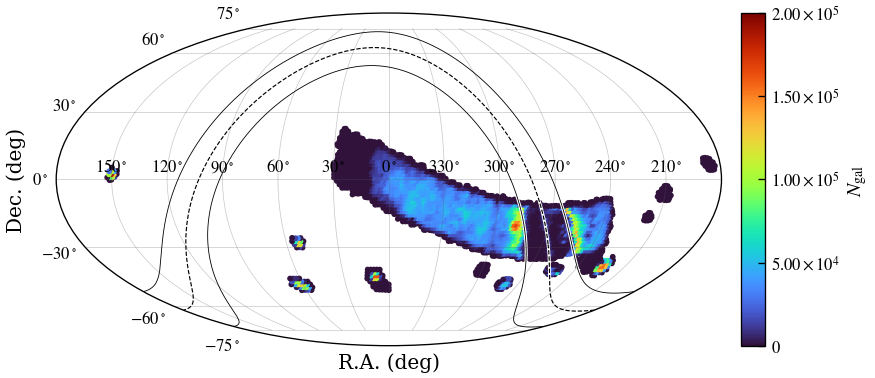

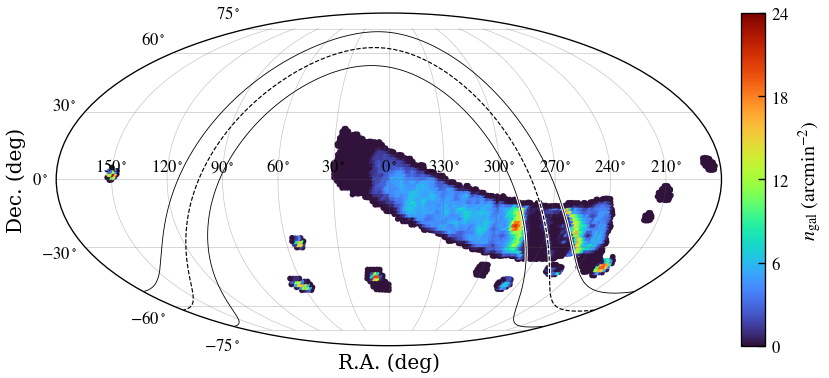

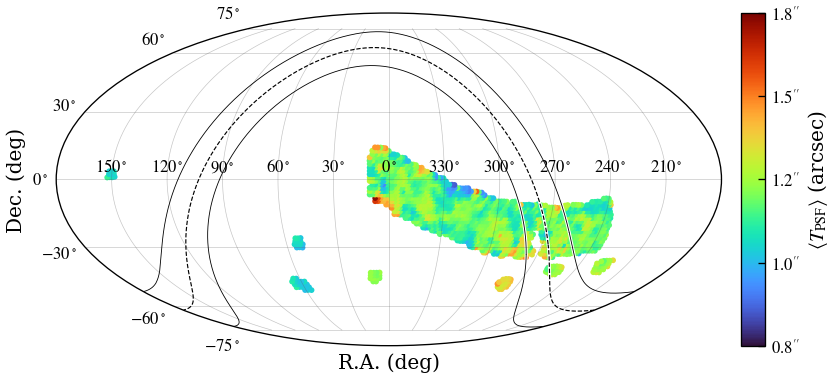

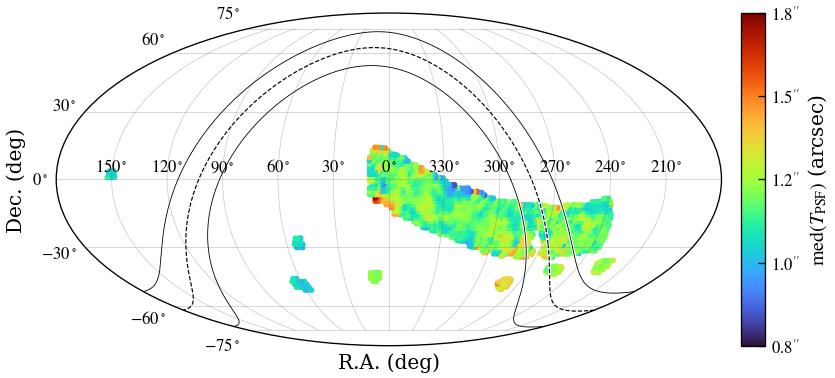

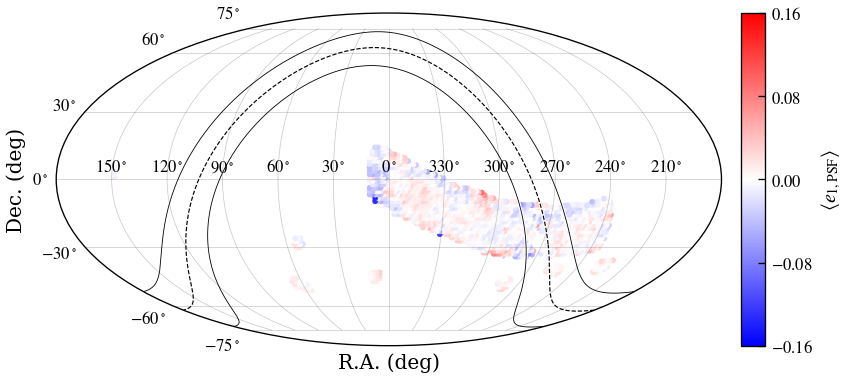

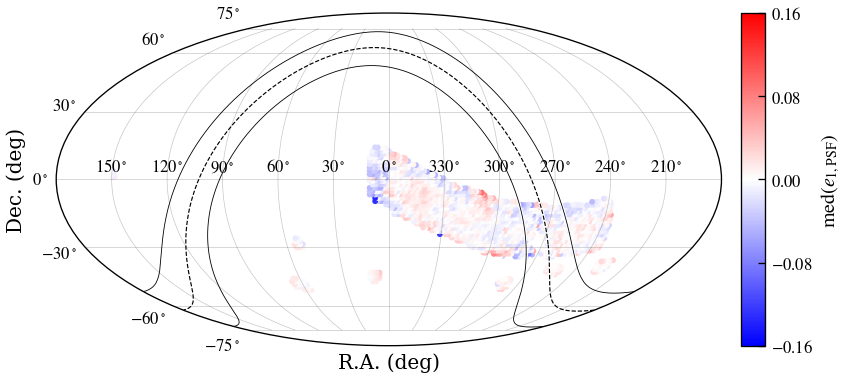

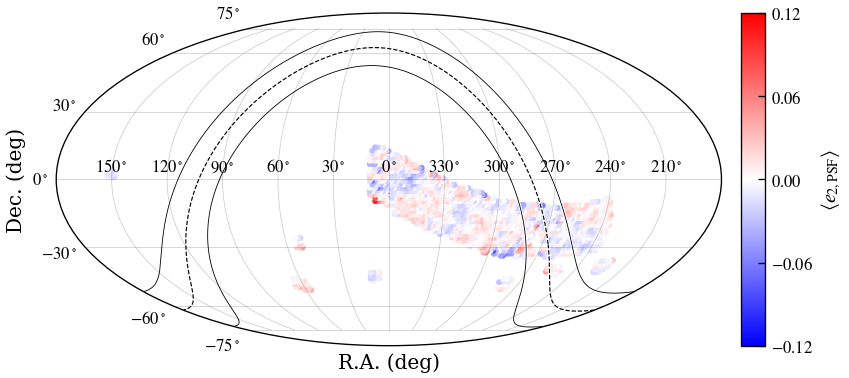

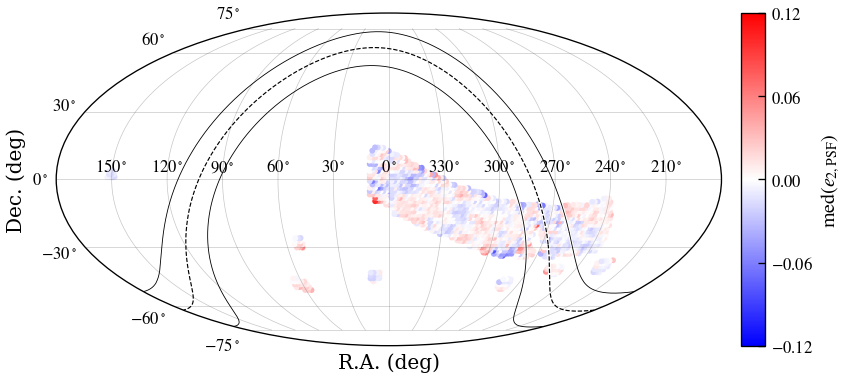

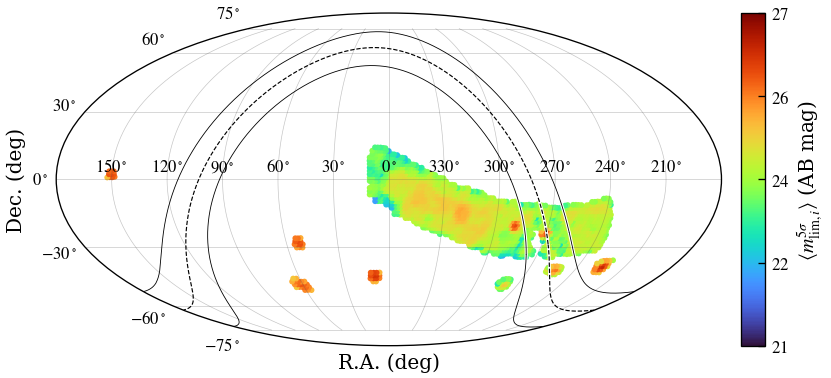

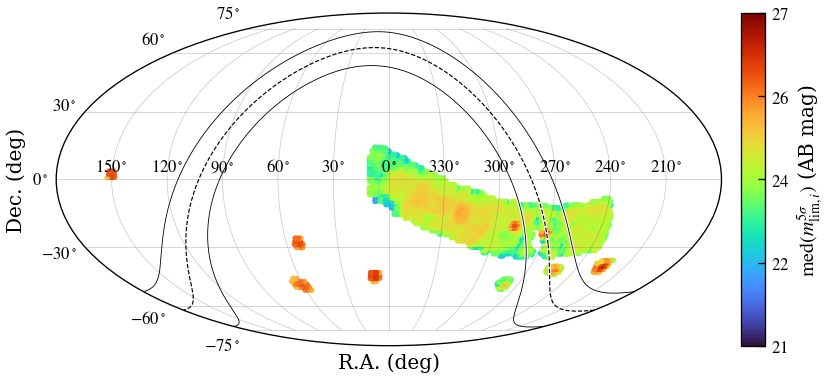

In [14]:
assert len(summary) > 0, "No tracts in the summary table; run section 5 first."

# Colorbar label is the quantity (no figure titles). Sequential: turbo; diverging: bwr.
plot_specs = [
    {
        "col": "n_gal",
        "label": r"Ngal",
        "diverging": False,
        "fname": "dp2_tract_n_gal.pdf",
    },
    {
        "col": "gal_density",
        "label": r" ngal (arcmin−2)",
        "diverging": False,
        "fname": "dp2_tract_gal_density.pdf",
    },
    {
        "col": "psf_fwhm_mean",
        "label": r"⟨TPSF⟩ (arcsec)",
        "diverging": False,
        "tick_unit": "arcsec",
        "fname": "dp2_tract_psf_fwhm_mean.pdf",
    },
    {
        "col": "psf_fwhm_median",
        "label": r"med(TPSF) (arcsec)",
        "diverging": False,
        "tick_unit": "arcsec",
        "fname": "dp2_tract_psf_fwhm_median.pdf",
    },
    {
        "col": "psf_e1_mean",
        "label": r"⟨e1,PSF⟩",
        "diverging": True,
        "fname": "dp2_tract_psf_e1_mean.pdf",
    },
    {
        "col": "psf_e1_median",
        "label": r"$\mathrm{med}(e_{1,\mathrm{PSF}})$",
        "diverging": True,
        "fname": "dp2_tract_psf_e1_median.pdf",
    },
    {
        "col": "psf_e2_mean",
        "label": r"$\langle e_{2,\mathrm{PSF}} \rangle$",
        "diverging": True,
        "fname": "dp2_tract_psf_e2_mean.pdf",
    },
    {
        "col": "psf_e2_median",
        "label": r"$\mathrm{med}(e_{2,\mathrm{PSF}})$",
        "diverging": True,
        "fname": "dp2_tract_psf_e2_median.pdf",
    },
    {
        "col": "maglim_mean",
        "label": r"$\langle m_{\mathrm{lim},i}^{5\sigma} \rangle$ (AB mag)",
        "diverging": False,
        "fname": "dp2_tract_maglim_mean.pdf",
    },
    {
        "col": "maglim_median",
        "label": r"$\mathrm{med}(m_{\mathrm{lim},i}^{5\sigma})$ (AB mag)",
        "diverging": False,
        "fname": "dp2_tract_maglim_median.pdf",
    },
]


def spec_limits(spec):
    values = np.asarray(summary[spec["col"]], dtype=float)
    if spec["diverging"]:
        vmin, vmax, ticks, _ = diverging_limits(values, center="auto")
        return vmin, vmax, ticks, "bwr"
    vmin, vmax, ticks = sequential_limits(values)
    return vmin, vmax, ticks, "turbo"


for spec in plot_specs:
    vmin, vmax, ticks, cmap = spec_limits(spec)
    plot_tracts_mollweide(
        summary[spec["col"]],
        cbar_label=spec["label"],
        cmap=cmap,
        vmin=vmin,
        vmax=vmax,
        ticks=ticks,
        fname=spec["fname"],
        tick_unit=spec.get("tick_unit"),
    )


## 7.0 Summary

Per-tract distributions of the quantities written to the ECSV. The table path is
printed again so it is easy to find after a long run.


table: /home/a/abrought/dp2/v2/dp2-clusters-shear-mapping/_data/dp2_shapehsm_tract_stats.ecsv
tracts: 2164
column                        min     median       mean        max
----------------------------------------------------------------
n_gal                           0  1.401e+04  2.245e+04  1.847e+05
gal_density                     0      1.729      2.772       22.8
psf_fwhm_mean              0.8536      1.186      1.187      1.729
psf_fwhm_median            0.8313      1.183      1.185       1.72
psf_e1_mean               -0.1355  0.0006159 -0.0002531    0.09212
psf_e1_median             -0.1372  0.0004158 -0.0003151    0.09148
psf_e2_mean              -0.08171  0.0004726 -0.0004522     0.1023
psf_e2_median            -0.08222  0.0001927 -0.0005052     0.1003
maglim_mean                 22.21       24.3      24.26      26.38
maglim_median               22.21      24.31      24.27      26.41


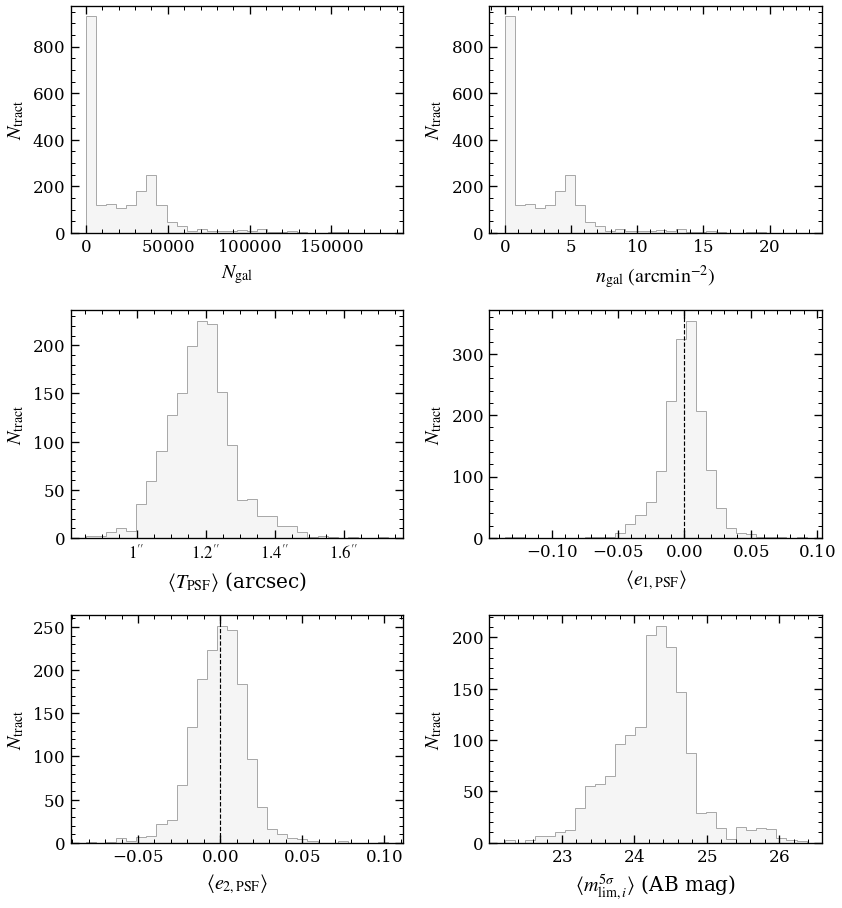

tract,ra_center,dec_center,n_before,n_gal,psf_fwhm_mean,psf_fwhm_median,psf_e1_mean,psf_e1_median,psf_e2_mean,psf_e2_median,maglim_mean,maglim_median,gal_density
int64,float64,float64,int64,int64,float64,float64,float64,float64,float64,float64,float64,float64,float64
2054,359.9984979417929,-51.31030099292582,118836,0,nan,nan,nan,nan,nan,nan,nan,nan,0.0
2055,2.4220023004696087,-51.1997313585473,167935,0,nan,nan,nan,nan,nan,nan,nan,nan,0.0
2056,4.714257370707681,-51.08424741162762,181402,0,nan,nan,nan,nan,nan,nan,nan,nan,0.0
2057,6.854742401965945,-51.03688349093169,156857,0,nan,nan,nan,nan,nan,nan,nan,nan,0.0
2058,9.01433246274937,-50.90489868133371,32718,0,nan,nan,nan,nan,nan,nan,nan,nan,0.0
2078,56.07921666199075,-51.27675296670552,311226,649,1.0395606017881915,1.04471991808753,0.010082107070452737,0.011405519172493724,0.03443070249469471,0.03590915465887814,25.040826554895286,25.05812887024858,0.08012345679012346
2079,58.470419058547606,-51.19407391802168,371100,19744,1.039031083079766,1.0374614265768451,0.0079223279225871,0.006185267508613802,0.024621532539805636,0.02366388837346014,25.313246009948482,25.34775311399739,2.437530864197531
2080,60.69318412004939,-51.245410351450396,357542,10356,1.011549663603854,1.010175321507797,0.008240217419234443,0.009745313033123365,0.02017983551049833,0.02172847840013796,25.44325471426122,25.478914160720926,1.2785185185185186
2081,63.12960188220475,-51.33512660902535,297158,0,nan,nan,nan,nan,nan,nan,nan,nan,0.0


In [15]:
print("table:", output_path)
print(f"tracts: {len(summary)}")
assert len(summary) > 0, "empty summary; run section 5 first"

cols = [
    "n_gal",
    "gal_density",
    "psf_fwhm_mean",
    "psf_fwhm_median",
    "psf_e1_mean",
    "psf_e1_median",
    "psf_e2_mean",
    "psf_e2_median",
    "maglim_mean",
    "maglim_median",
]
print(f"{'column':<22} {'min':>10} {'median':>10} {'mean':>10} {'max':>10}")
print("-" * 64)
for col in cols:
    x = np.asarray(summary[col], dtype=float)
    x = x[np.isfinite(x)]
    if x.size == 0:
        print(f"{col:<22} {'nan':>10}")
        continue
    print(
        f"{col:<22} {np.min(x):10.4g} {np.median(x):10.4g} {np.mean(x):10.4g} {np.max(x):10.4g}"
    )

hist_specs = [
    ("n_gal", r"Ngal"),
    ("gal_density", r" ngal (arcmin−2)"),
    ("psf_fwhm_mean", r"⟨TPSF⟩ (arcsec)"),
    ("psf_e1_mean", r"⟨e1,PSF⟩"),
    ("psf_e2_mean", r"⟨e2,PSF⟩"),
    ("maglim_mean", r"$\langle m_{\mathrm{lim},i}^{5\sigma} \rangle$ (AB mag)"),
]

n_hist = len(hist_specs)
n_col = 2
n_row = int(np.ceil(n_hist / n_col))
fig, axes = plt.subplots(n_row, n_col, figsize=(7.25, 2.6 * n_row))
axes = np.atleast_1d(axes).ravel()
for ax, (col, label) in zip(axes, hist_specs):
    x = np.asarray(summary[col], dtype=float)
    x = x[np.isfinite(x)]
    ax.hist(x, bins=30, histtype="stepfilled", color="whitesmoke", edgecolor="darkgray", linewidth=0.6)
    ax.set_xlabel(label)
    ax.set_ylabel(r"$N_{\mathrm{tract}}$")
    if col.startswith("psf_fwhm"):
        ax.xaxis.set_major_formatter(lambda v, _: rf"${v:g}''$")
    if col.startswith("psf_e"):
        ax.axvline(0.0, color="k", linewidth=0.7, linestyle="--")
for ax in axes[n_hist:]:
    ax.set_visible(False)
fig.tight_layout()
save_figure(fig, "dp2_tract_stats_hist.pdf")
plt.show()

summary


## 8.0 Source density, depth, and seeing

Helper for density contours, then tract-level cuts and the density-depth relation.


In [16]:
from matplotlib.colors import LinearSegmentedColormap, to_rgb
from matplotlib.lines import Line2D


def plot_hexbin_contours(x, y, ax=None, gridsize=40, bins=50, levels=(1, 2, 3),
                         smooth=None, color="cornflowerblue", cmap=None,
                         contour_color=None, linewidths=1.5, fill=False,
                         alpha=0.25, min_count=1, label=None, **hexbin_kwargs):
    """
    Sigma contours of the 2D density of (x, y). The hexbin itself is drawn by the caller;
    gridsize, cmap and hexbin_kwargs are currently unused.

    gridsize      : hexbin resolution
    bins          : resolution of the rectangular grid used for the contours
    levels        : contour levels in units of sigma (2D Gaussian equivalent)
    smooth        : Gaussian sigma in units of bins; None disables smoothing
    min_count     : bins with counts <= this are zeroed before contouring
                    (hexbin still shows them via mincnt=1)
    fill          : shaded stacked contours instead of lines
    contour_color : defaults to a darkened version of `color`
    """
    if ax is None:
        ax = plt.gca()

    x = np.asarray(x, dtype=float)
    y = np.asarray(y, dtype=float)
    good = np.isfinite(x) & np.isfinite(y)
    x, y = x[good], y[good]

    if cmap is None:
        cmap = LinearSegmentedColormap.from_list(
            "mono", ["white", color, tuple(0.45 * c for c in to_rgb(color))])
    if contour_color is None:
        contour_color = tuple(0.55 * c for c in to_rgb(color))

    extent = (x.min(), x.max(), y.min(), y.max())

    # Contour field on a rectangular grid over the same extent
    H_raw, xedges, yedges = np.histogram2d(
        x, y, bins=bins, range=[extent[:2], extent[2:]])
    H = np.where(H_raw <= min_count, 0.0, H_raw).T

    if smooth:
        from scipy.ndimage import gaussian_filter
        H = gaussian_filter(H, smooth)

    xc = 0.5 * (xedges[1:] + xedges[:-1])
    yc = 0.5 * (yedges[1:] + yedges[:-1])

    total = H.sum()
    thresholds = np.array([])
    if total > 0:
        fractions = 1.0 - np.exp(-0.5 * np.atleast_1d(levels) ** 2)
        flat = np.sort(H.ravel())[::-1]
        csum = np.cumsum(flat) / total
        thresholds = np.unique([flat[np.argmax(csum >= f)] for f in fractions])
        thresholds = thresholds[thresholds > 0]

    # Thresholds enclose the probability mass of a 2D Gaussian within each sigma level.
    if len(thresholds):
        if fill:
            for t in thresholds:  # widest first, alphas compound inward
                ax.contourf(xc, yc, H, levels=[t, H.max() + 1.0],
                            colors=[contour_color], alpha=alpha, zorder=3)
        else:
            ax.contour(xc, yc, H, levels=thresholds, colors=[contour_color],
                       linewidths=linewidths, zorder=3)

    if label is not None:
        ax.add_line(Line2D([], [], color=contour_color,
                           linewidth=linewidths, label=label))

    return ax

### Tract cuts

Keep tracts with source density above 0.3 arcmin$^{-2}$, $|b| > 15^{\circ}$, and outside
the rim of the ecliptic SV strip. The two Mollweide panels show the footprint before
and after.


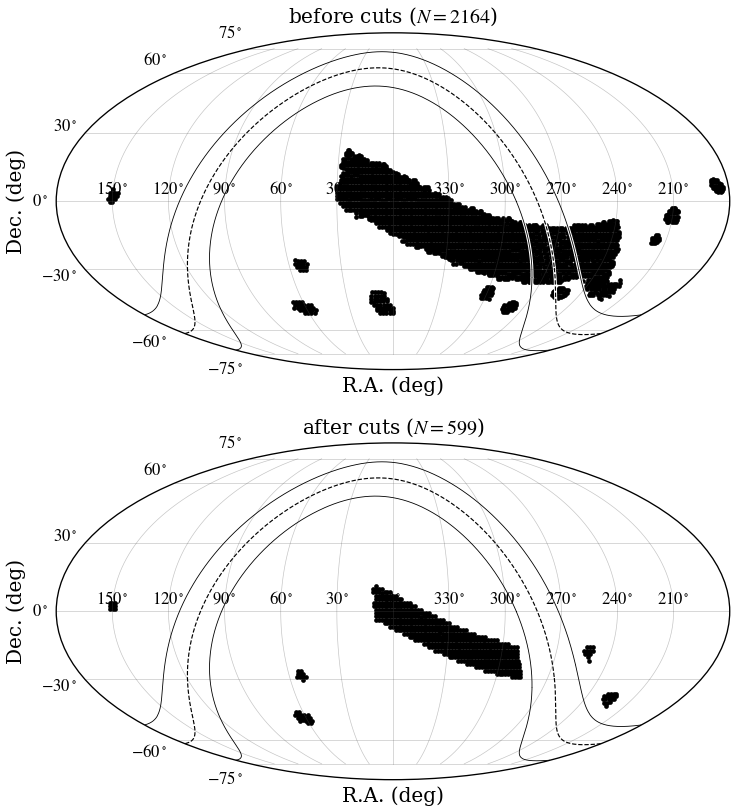

In [48]:
# Tract quality cuts: minimum source density, galactic latitude, and the SV-strip rim.
trim = (summary['gal_density'] > 0.3)

# Remove any tracts within the galactic plane:
coords = SkyCoord(ra=summary["ra_center"] * u.deg, dec=summary["dec_center"] * u.deg, frame="icrs")
trim &= np.abs(coords.galactic.b.deg) > 15

# Remove tracts near the ecliptic SV-strip rim. The strip runs RA ~240°→30°
# (through 0), |β| ≲ 10°. in_sv is padded a few degrees past the RA ends so
# tract centers sitting on the RA=240° rim are counted as in-strip; only the
# interior (RA 250°→20°, |β| < 7°) is kept.
ra = np.asarray(summary["ra_center"]) % 360.0
beta = np.abs(coords.barycentrictrueecliptic.lat.deg)
in_sv = (ra >= 235.0) | (ra <= 35.0)
sv_interior = ((ra > 250.0) | (ra < 20.0)) & (beta < 7.0)
trim &= ~in_sv | sv_interior

# Split the kept tracts by mean PSF FWHM: lowest third vs the upper two thirds.
bounds = np.linspace(np.nanmin(summary['psf_fwhm_mean']), np.nanmax(summary['psf_fwhm_mean']), 3+1)
psf_cut_1 = trim * (summary['psf_fwhm_mean'] >= bounds[0]) * (summary['psf_fwhm_mean'] < bounds[1])
psf_cut_2 = trim * (summary['psf_fwhm_mean'] >= bounds[1]) * (summary['psf_fwhm_mean'] <= bounds[3])

# Plot the cuts to tracts here
lon, lat = ra_dec_to_mollweide(summary["ra_center"], summary["dec_center"])
kept = np.asarray(trim, dtype=bool)

fig, axes = plt.subplots(2, 1, figsize=(7.25, 7.0), subplot_kw={"projection": "mollweide"})
for ax, mask, label in (
    (axes[0], np.ones(len(summary), dtype=bool), "before cuts"),
    (axes[1], kept, "after cuts"),
):
    ax.scatter(lon[mask], lat[mask], s=8, c="k", linewidths=0, rasterized=True)
    _draw_galactic_plane(ax)
    _style_mollweide(ax)
    ax.set_title(rf"{label} ($N={int(mask.sum())}$)")
fig.tight_layout()
save_figure(fig, "dp2_tract_stats_cuts_mollweide.pdf")
plt.show()

### Source density vs depth

Hexbin of source density against mean i-band 5σ depth for the kept tracts, with
contours for the two PSF-size bins and a power-law fit
$n_{\rm gal} = a \times 10^{b(i - 25)}$.


7.385014481144362 0.3384253861061995


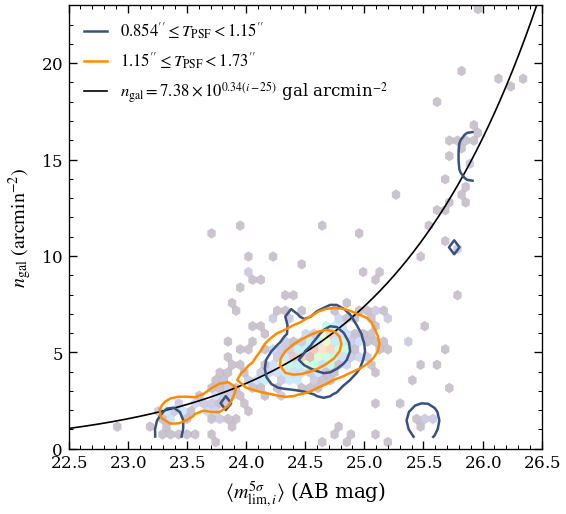

In [50]:
plt.figure()
plt.hexbin(summary[trim]['maglim_mean'], summary[trim]['gal_density'], mincnt=1, gridsize=50, linewidth=0.05,alpha=0.25)
plot_hexbin_contours(summary[psf_cut_1]['maglim_mean'], summary[psf_cut_1]['gal_density'], gridsize=50,levels=(1,2), smooth=1.5, label=rf"${bounds[0]:.3g}'' \leq T_{{\rm{{PSF}}}} < {bounds[1]:.3g}''$")
plot_hexbin_contours(summary[psf_cut_2]['maglim_mean'], summary[psf_cut_2]['gal_density'], gridsize=50,levels=(1,2), contour_color="darkorange", smooth=1.5, label=rf"${bounds[1]:.3g}'' \leq T_{{\rm{{PSF}}}} < {bounds[3]:.3g}''$")


plt.gca().set_aspect(1/(23./2.5) * 1.5)
plt.gca().set_xlabel(r"⟨mlim,i5σ⟩ (AB mag)")
plt.gca().set_ylabel(r" ngal (arcmin−2)")

from scipy.optimize import curve_fit

def gal_density_model(i_mag, a, b):
    return a * 10**(b*(i_mag-25.0))

popt, pcov = curve_fit(gal_density_model, summary[trim]['maglim_mean'], summary[trim]['gal_density'], sigma=1/np.sqrt(summary[trim]['n_gal']))
print(*popt)
plt.plot(np.linspace(22.5,26.5, 1000), gal_density_model(np.linspace(22.5,26.5, 1000), *popt), color="k"
        , label=r"ngal=7.38×100.34(i−25) gal arcmin−2")
plt.ylim(0,23)
plt.xlim(22.5,26.5)

plt.legend(loc="upper left", frameon=False)
save_figure(plt.gcf(), "dp2_tract_stats_maglim_density.pdf")
